In [1]:
%load_ext autoreload
%autoreload 2

[ 3  4  5  6  7 16 17 23 24 25 26 27]


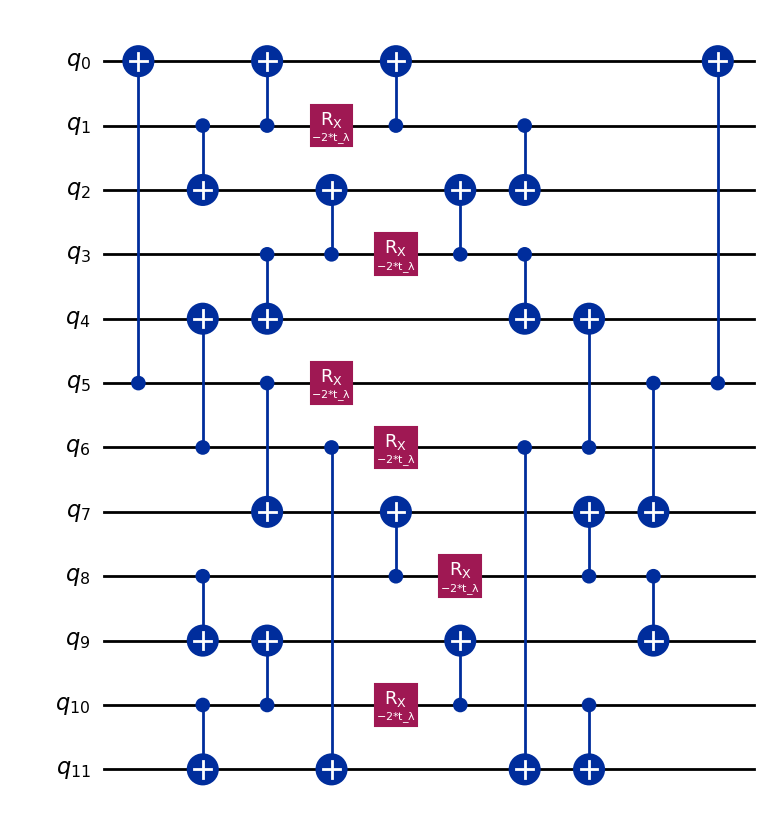

In [2]:
from z2hex.circs import TotalInteractionPropagator
from z2hex.geometry import HeavyHexLattice
lattice = HeavyHexLattice(plaq_width=1,plaq_height=1)
initial_qubit_layout = lattice.initial_qubit_layout(backend='ibm_fez')
print(initial_qubit_layout)
circuit = TotalInteractionPropagator(lattice)
circuit.draw('mpl')


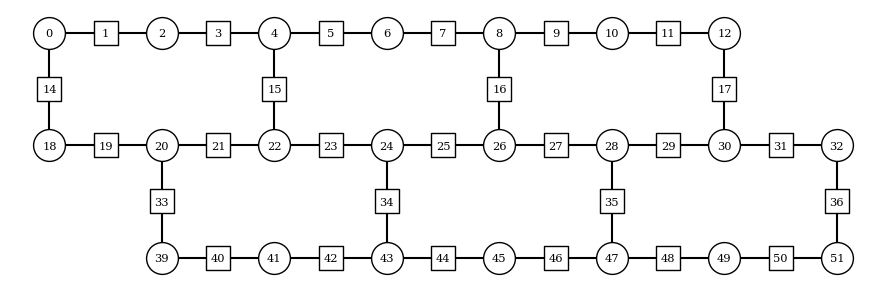

In [3]:
from z2hex.geometry import HeavyHexLattice

lattice = HeavyHexLattice(plaq_width=3, plaq_height=2)
lattice.plot_lattice(number_qubits=True, backend="ibm_brisbane")

In [4]:
from z2hex.circs import get_erradj_string_quench_simulation_circuits
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance2

service = QiskitRuntimeService(channel="ibm_quantum", token=ibm_token, instance=group_instance2)
backend = service.backend("ibm_fez")

circs = get_erradj_string_quench_simulation_circuits(lattice, 1, 0.05, 0.7, [4, 10, 18, 17, 16, 24, 30], 8, 35, backend, optimization_level=2, eplg_absolute=4.49e-3, g=None, layout_first_qubit=3)

ImportError: cannot import name 'get_erradj_string_quench_simulation_circuits' from 'z2hex.circs' (/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/z2hex/circs.py)

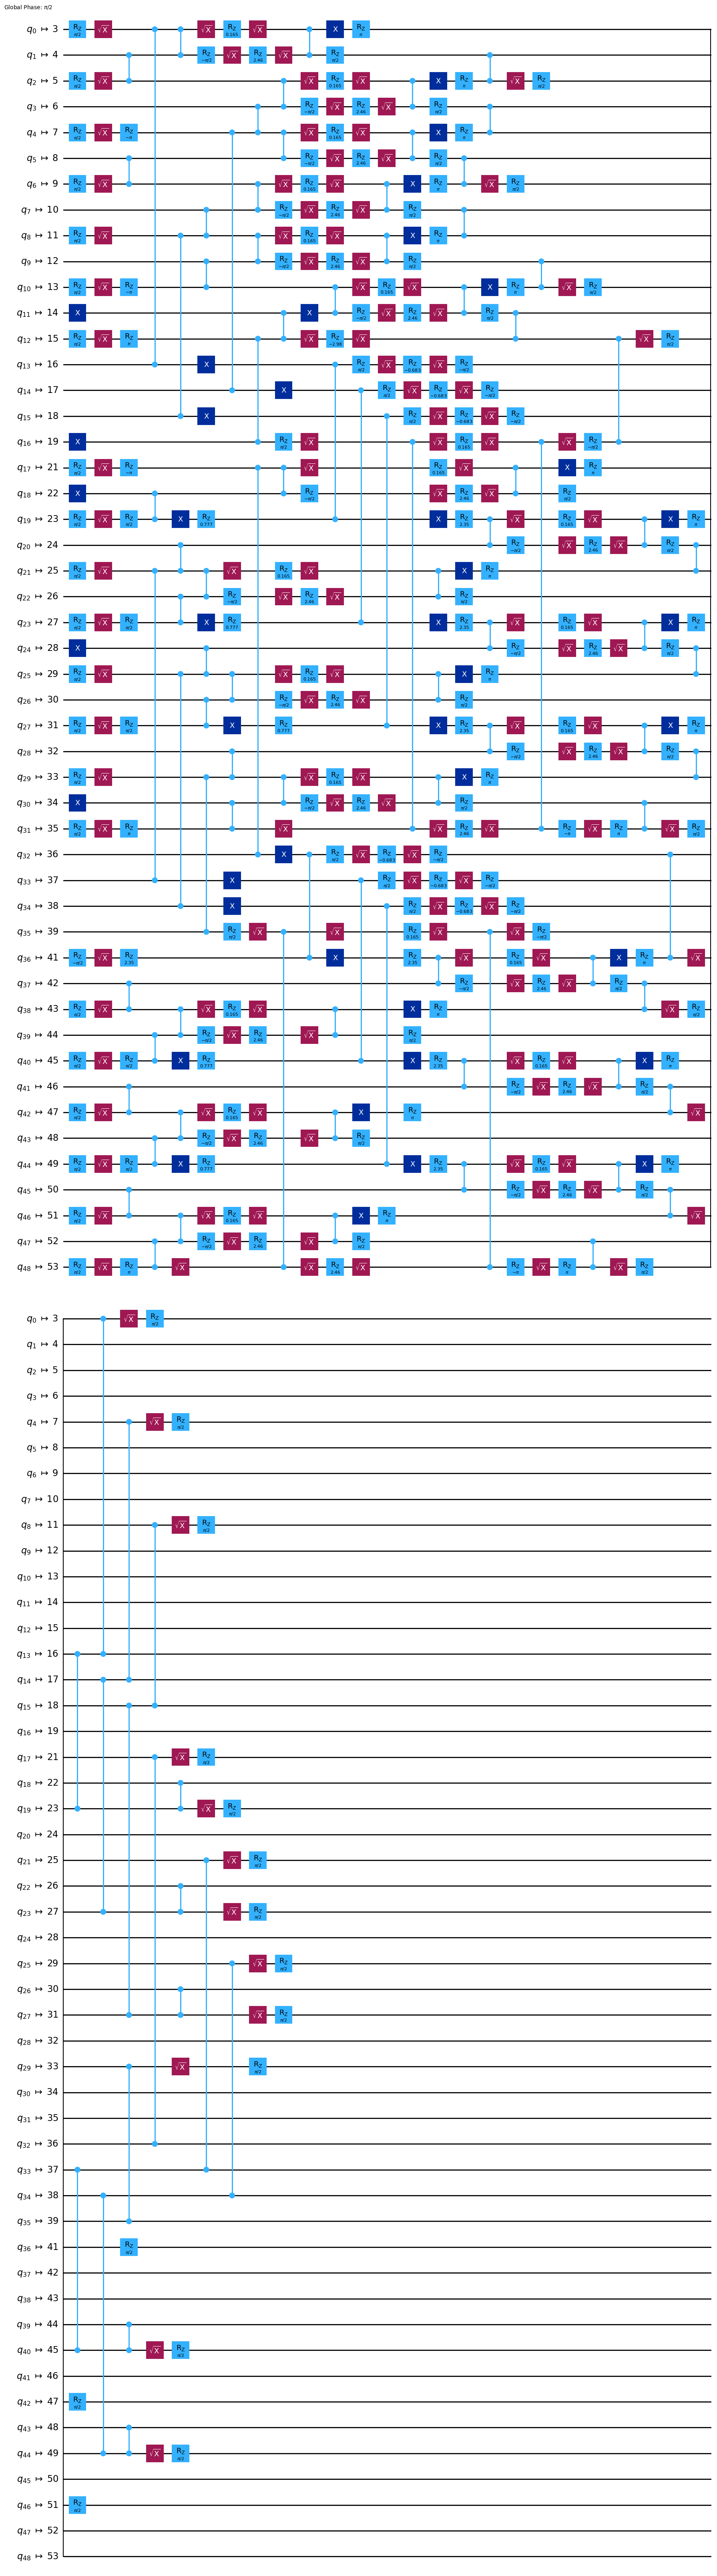

In [ ]:
circs[1].draw(output="mpl", idle_wires=False)

# Plots

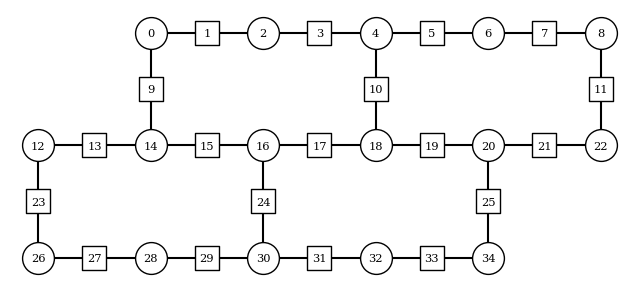

In [ ]:
from z2hex.geometry import HeavyHexLattice
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance2

lattice = HeavyHexLattice(2, 2)
lattice.plot_lattice(number_qubits=True)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_18425/1437776754.py:66: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(vertex_x, vertex_y, 350*scale, marker="o", c=this_node_color, edgecolors="black", zorder=3)
/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_18425/1437776754.py:60: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(this_edge_box_x, this_edge_box_y, 400*scale, marker=(4

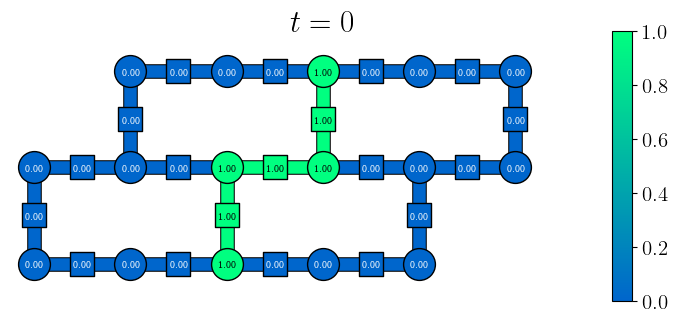

In [ ]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

example_site_gauge_observable_matrix = np.array([0,0,0,0,1,0,0,0,0,\
                                                 0,      1,      0,\
                                             0,0,0,0,1,1,1,0,0,0,0,\
                                             0,      1,      0,\
                                             0,0,0,0,1,0,0,0,0])

# example_site_gauge_observable_matrix = np.ones(len(lattice), int)

def is_edge_coords(coords):
    if type(coords) == tuple:
        return (coords[0] % 1 != 0) or (coords[1] % 1 != 0)
    else:
        try:
            coords = np.array(coords)
            return ~np.equal(coords.sum(axis=1) % 1, 0)
        except np.AxisError:
            raise np.AxisError("Coords is not a valid tuple or N x 2 array")
        
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

def local_observable_plot(site_gauge_matrix_observable_arr, lattice, scale=1.5, title=None, dark_theme=False, filepath=""):
    plt.rc("text", usetex=True)
    plt.rc("font", size=24, family="serif", weight="bold")

    vertices_coords = sorted(list(lattice.vertices.keys()))
    edges_coords = sorted(list(lattice.edges.keys()))
    all_coords = np.array(sorted(vertices_coords + edges_coords))
    is_edge_coords_arr = is_edge_coords(all_coords)

    if dark_theme:
        facecolor = "#373737"
        cmap = plt.get_cmap("inferno")
    else:
        facecolor = "white"
        cmap = truncate_colormap(plt.get_cmap("winter"), 0.4, 1)

    fig, ax = plt.subplots(figsize=[(scale + 0.5)*lattice.max_x, scale*lattice.max_y], facecolor=facecolor)
    ax.set_aspect('equal')
    scalar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=1))
    data_cmap_norm = np.max(site_gauge_matrix_observable_arr) - np.min(site_gauge_matrix_observable_arr)
    tdowntransform = mpl.transforms.Affine2D().translate(0, -1*scale)
    trighttransform = mpl.transforms.Affine2D().translate(0.035*scale, 0)
    for i, (y, x) in enumerate(all_coords):
        if is_edge_coords_arr[i]:
            this_edge_endpoints_x = (np.floor(x), np.ceil(x))
            this_edge_endpoints_y = (lattice.max_y - np.floor(y), lattice.max_y - np.ceil(y))
            this_edge_box_x, this_edge_box_y = np.mean([this_edge_endpoints_x, this_edge_endpoints_y], axis=1)
            this_edge_color = cmap(this_norm_data := site_gauge_matrix_observable_arr[i]/data_cmap_norm)
            plt.plot(this_edge_endpoints_x, this_edge_endpoints_y, color="black", linewidth=7*scale)
            plt.plot(this_edge_endpoints_x, this_edge_endpoints_y, color=this_edge_color, linewidth=6*scale)
            plt.scatter(this_edge_box_x, this_edge_box_y, 400*scale, marker=(4, 0, 45), c=this_edge_color, edgecolors="black", zorder=2)
            text_color = "black" if this_norm_data > 0.5 else "white"
            text = plt.text(this_edge_box_x, this_edge_box_y, f"{site_gauge_matrix_observable_arr[i]:.02f}", color=text_color, horizontalalignment="center", verticalalignment="center", fontdict={"size": 4.5*scale, "family":"serif"})
        else:
            vertex_x, vertex_y = x, lattice.max_y - y
            this_node_color = cmap(this_norm_data := site_gauge_matrix_observable_arr[i]/data_cmap_norm)
            plt.scatter(vertex_x, vertex_y, 350*scale, marker="o", c=this_node_color, edgecolors="black", zorder=3)
            text_color = "black" if this_norm_data > 0.5 else "white"
            text = plt.text(vertex_x, vertex_y, f"{site_gauge_matrix_observable_arr[i]:.02f}", c=text_color, horizontalalignment="center", verticalalignment="center", fontdict={"size": 4.5*scale, "family":"serif"})
        text.set_transform(text.get_transform() + tdowntransform + trighttransform)
    plt.axis("off")
    plt.ylim([-0.2, lattice.max_y + 0.2])
    cax = fig.add_axes([0.85, 0.05, 0.02, 0.9])
    cax.tick_params(labelsize=15)
    plt.colorbar(scalar_mappable, cax)
    nqbfirstrow = len([coords for coords in lattice.coords if coords[0]==0])
    ax.text(lattice.coords[:nqbfirstrow][nqbfirstrow//2][1], lattice.max_y + 0.5, title, horizontalalignment="center", verticalalignment="center", fontdict={"family":"serif", "size": 15*scale})
    if filepath:
        plt.savefig(filepath, dpi=300, bbox_inches="tight")
    plt.rcdefaults()

local_observable_plot(example_site_gauge_observable_matrix, lattice, title="$t=0$", dark_theme=False)

In [ ]:
from z2hex.plotting import local_obs_anim

example_site_gauge_observable_matrix_1 = np.array([0,0,0,0,1,0,0,0,0,\
                                                   0,      1,      0,\
                                               0,0,0,0,1,1,1,0,0,0,0,\
                                               0,      1,      0,\
                                               0,0,0,0,1,0,0,0,0])

example_site_gauge_observable_matrix_2 = np.array([0,0,0,0,1,0,0,0,0,\
                                                   0,      1,      0,\
                                               0,0,0,0,0,0,0,1,1,0,0,\
                                               0,      0,      1,\
                                               0,0,0,0,1,1,1,1,1])

example_site_gauge_observable_matrix_3 = np.array([0,0,0,0,1,0,0,0,0,\
                                                   0,      1,      0,\
                                               0,0,0,0,1,1,1,0,0,0,0,\
                                               0,      1,      0,\
                                               0,0,0,0,1,0,0,0,0])

example_site_gauge_observable_matrix_4 = np.array([0,0,0,0,1,0,0,0,0,\
                                                   0,      1,      0,\
                                               0,0,0,0,0,0,0,1,1,0,0,\
                                               0,      0,      1,\
                                               0,0,0,0,1,1,1,1,1])

examples_site_gauge_observable_matrix = np.vstack((example_site_gauge_observable_matrix_1, example_site_gauge_observable_matrix_2, example_site_gauge_observable_matrix_3, example_site_gauge_observable_matrix_4))

local_obs_anim(examples_site_gauge_observable_matrix, lattice, interpolation_frames=89, step_to_title_function=lambda frame: f"$t = {frame/90:.02f}$")

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

# Result tests

In [4]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"

first_layout_qubit = 83
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

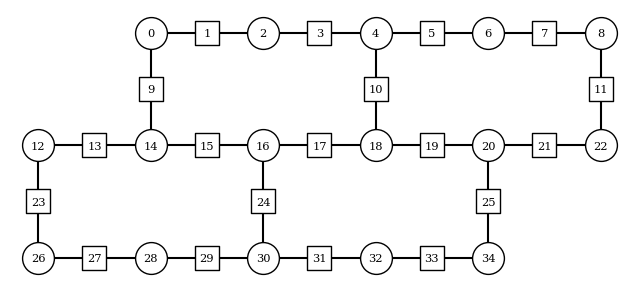

In [1]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

In [7]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

lattice_dims_arr = [(1, 1)]
J_arr = [1]
h_arr = [0.8]
lamb_arr = [0.3]
g_arr = [8]

x_basis = False

fractional_gates = False

# strings_arr = [[6, 7, 8, 16, 26, 25, 24, 34, 43, 44, 45, 54, 64, 63, 62, 72, 81, 82, 83, 92, 102, 101, 100]]
strings_arr = [[0, 1, 2, 3, 4, 6, 11]]

final_time = 5
steps = 35

max_layers = 50

shots = 75000

odr = True
flip_threshold = 2

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

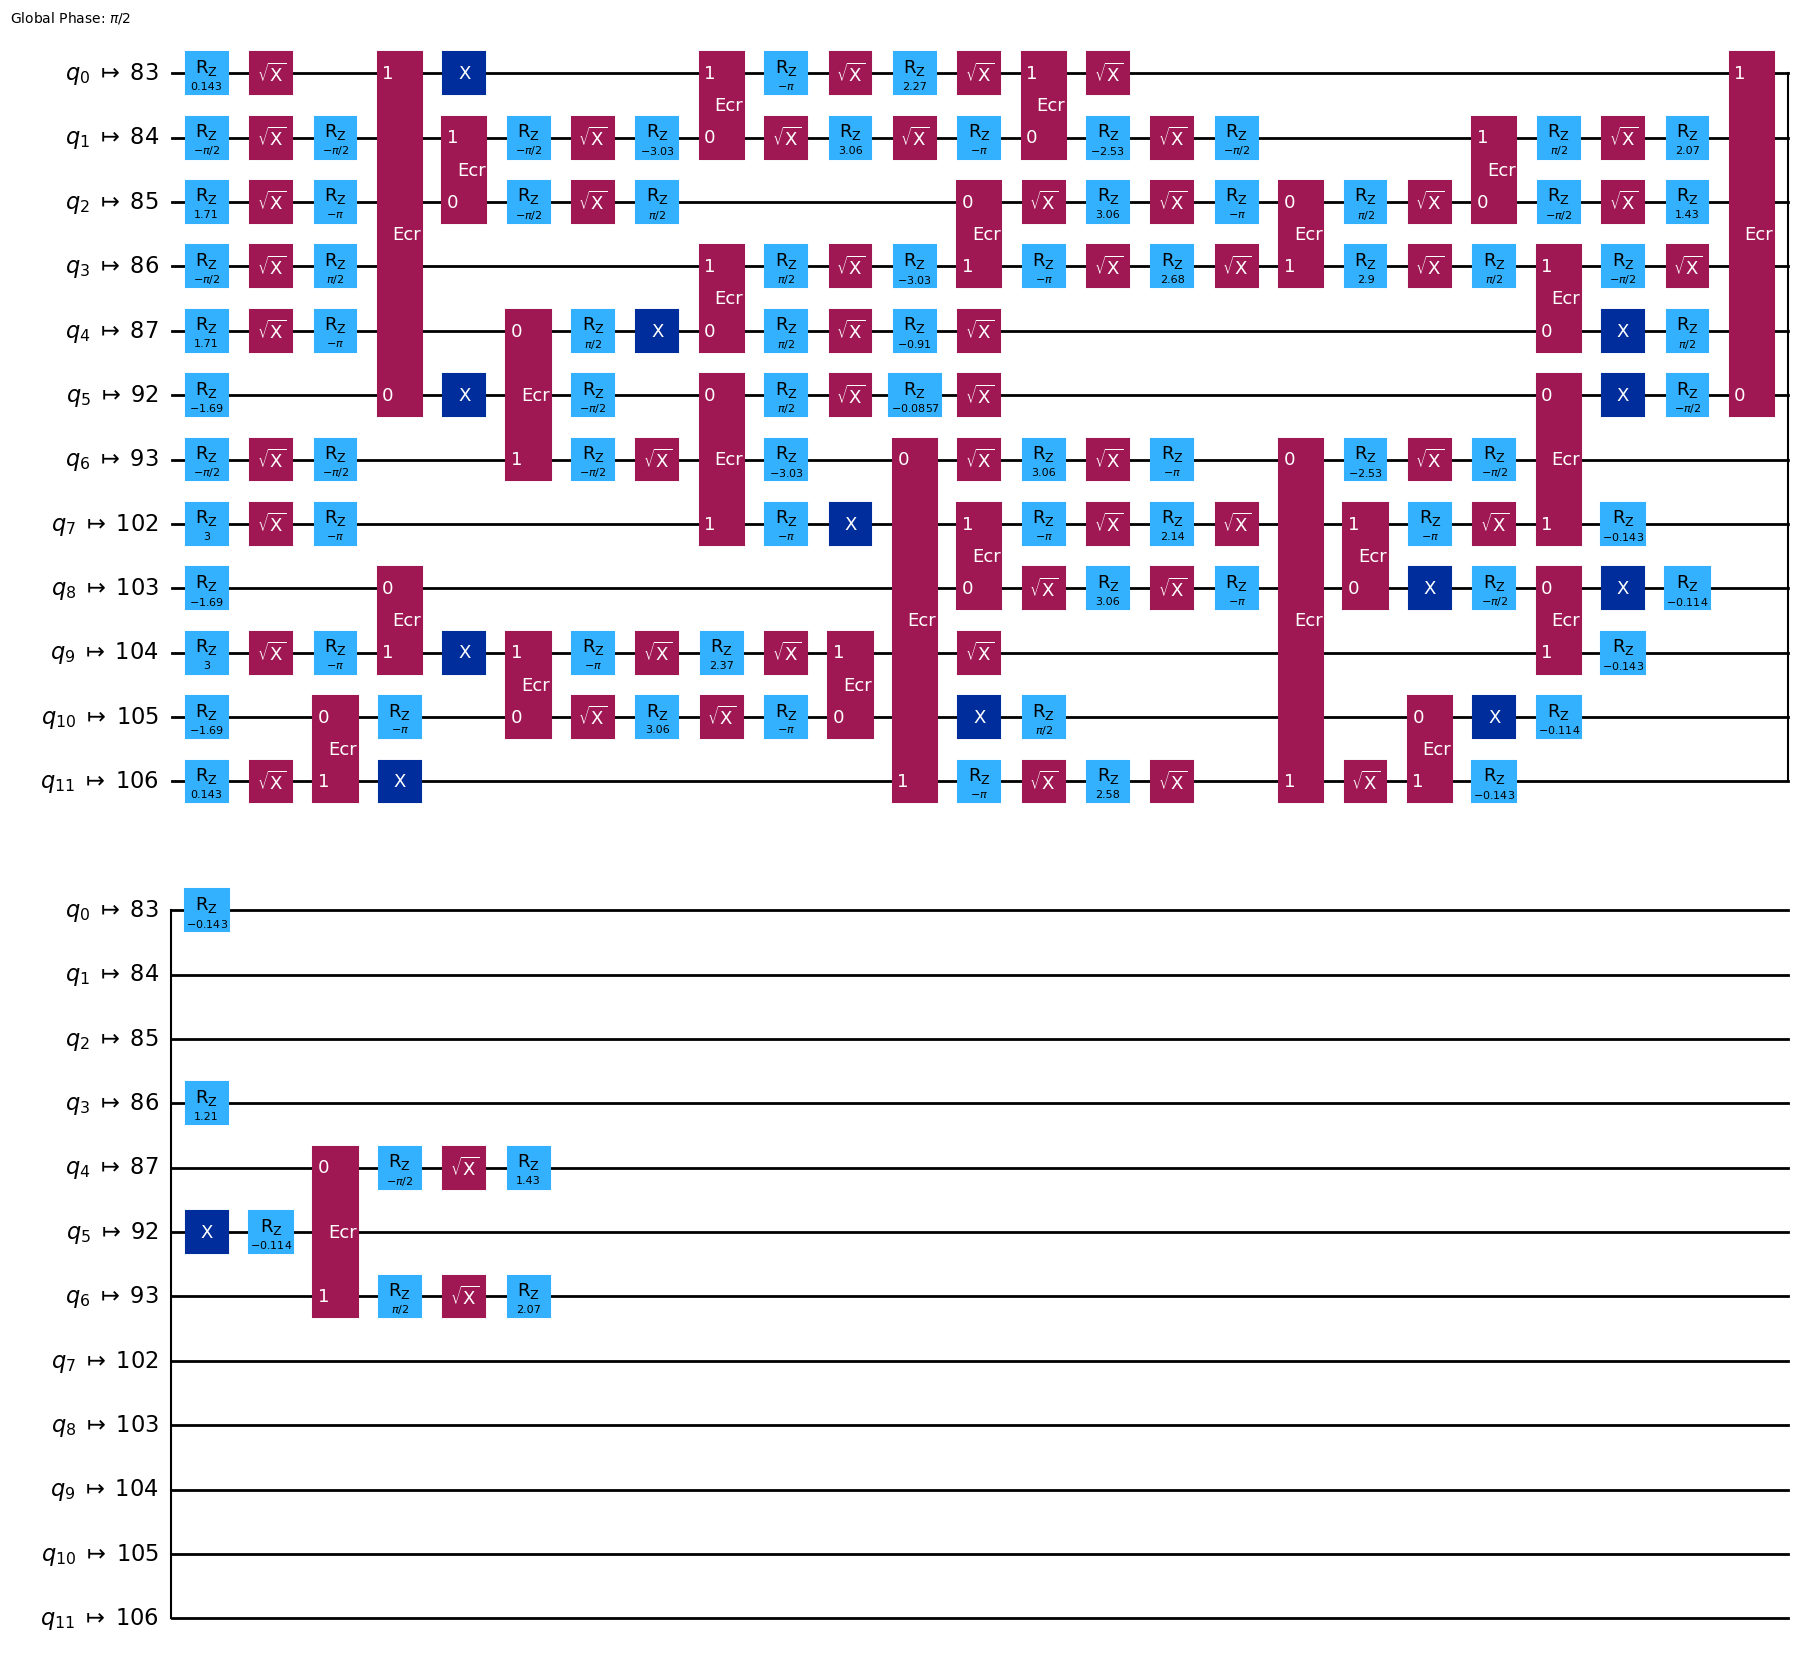

In [4]:
from z2hex.circs import erradj_string_quench_simulation_circuits_eplg, odr_compuncomp_circuits_eplg
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, steps, backend, optimization_level, eplg_absolute, g, first_layout_qubit, x_basis, False, max_layers)
        physical_circuits = erradj_string_quench_simulation_circuits_eplg(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "eplg": eplg_absolute} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (lattice, J, h, lamb, final_time, steps, backend, eplg_absolute, g, string_arr, first_layout_qubit, x_basis, False, max_layers)
            this_odr_circuits.append(odr_compuncomp_circuits_eplg(*odr_func_args))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

circuits[0][0][1].draw(output="mpl", idle_wires=False)

In [9]:
from utils.postselection import load_postselected_jobs
from itertools import product

observables = [] # jobs[dims][Jhλg][t]
samples_dicts = [] # samples_dicts[dims][Jhλg][t]
postselected_samples_dicts = [] # postselected_samples_dicts[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_observables = []
    this_dims_samples_dicts = []
    this_dims_postselected_samples_dicts = []
    for j, (Ji, hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        clean_extra_options = extra_options[i][j].copy()
        del clean_extra_options["eplg"]
        if odr:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, odr_circuits=odr_circuits[i][j], max_shots=shots)
        else:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, max_shots=shots)
        this_dims_observables.append(this_observables[0])
        this_dims_samples_dicts.append(this_samples_dicts[0])
        this_dims_postselected_samples_dicts.append(this_postselected_samples_dicts[0])
    observables.append(this_dims_observables)
    samples_dicts.append(this_dims_samples_dicts)
    postselected_samples_dicts.append(this_dims_postselected_samples_dicts)

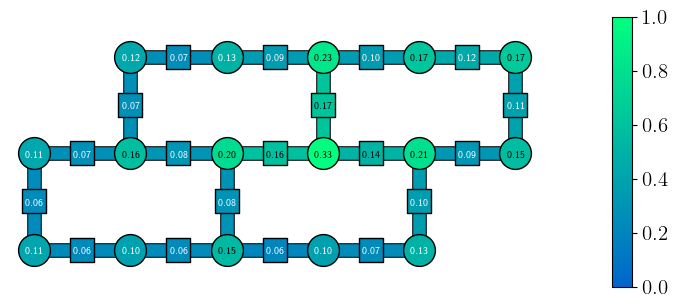

In [14]:
from z2hex.plotting import local_observable_plot

local_observable_plot((1-observables[0][0][0])/2, lattice)

## Clifford simulation of the state preparation circuit to check

In [1]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"

first_layout_qubit = 83
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

In [2]:
from qiskit_aer import AerSimulator

sampler_options = {"default_shots": 50000}

simulator_options = {
    "method": "stabilizer"
}

# fake_backend = AerSimulator(**simulator_options, target=backend.target)
fake_backend = AerSimulator.from_backend(backend)

from z2hex.circs import erradj_string_quench_simulation_circuits_eplg, odr_compuncomp_circuits_eplg
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, steps, fake_backend, optimization_level, eplg_absolute, g, first_layout_qubit, x_basis, False, max_layers)
        physical_circuits = erradj_string_quench_simulation_circuits_eplg(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "eplg": eplg_absolute} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (lattice, J, h, lamb, final_time, steps, fake_backend, eplg_absolute, g, string_arr, first_layout_qubit, x_basis, False, max_layers)
            this_odr_circuits.append(odr_compuncomp_circuits_eplg(*odr_func_args))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

circuits[0][0][1].draw(output="mpl", idle_wires=False)

NameError: name 'odr' is not defined

In [ ]:
from utils.postselection import simulate_postselected_operators
from z2hex.plotting import local_observable_plot, local_obs_anim
from itertools import product

sampler_options = sampler_options = {
    "default_shots": 50000,
}

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

observables = simulate_postselected_operators(fake_backend, sampler_options, circuits[0][0], postselection_operators_funcs[0], observable_generating_funcs[0])
local_obs_anim((1 - observables)/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, filepath=f"z2hex_string_quench_simulation_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4")

IndexError: tuple index out of range

In [15]:
local_obs_anim((1 - observables)/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, filepath=f"z2hex_string_quench_simulation_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4")

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

In [22]:
observables[1]

array([-4.000e-05,  1.760e-03,  1.440e-03,  5.360e-03, -1.004e-02,
       -8.040e-03, -1.680e-03, -2.920e-03, -2.800e-04,  6.240e-03,
        6.000e-04, -1.480e-03])

## Noiseless simulation

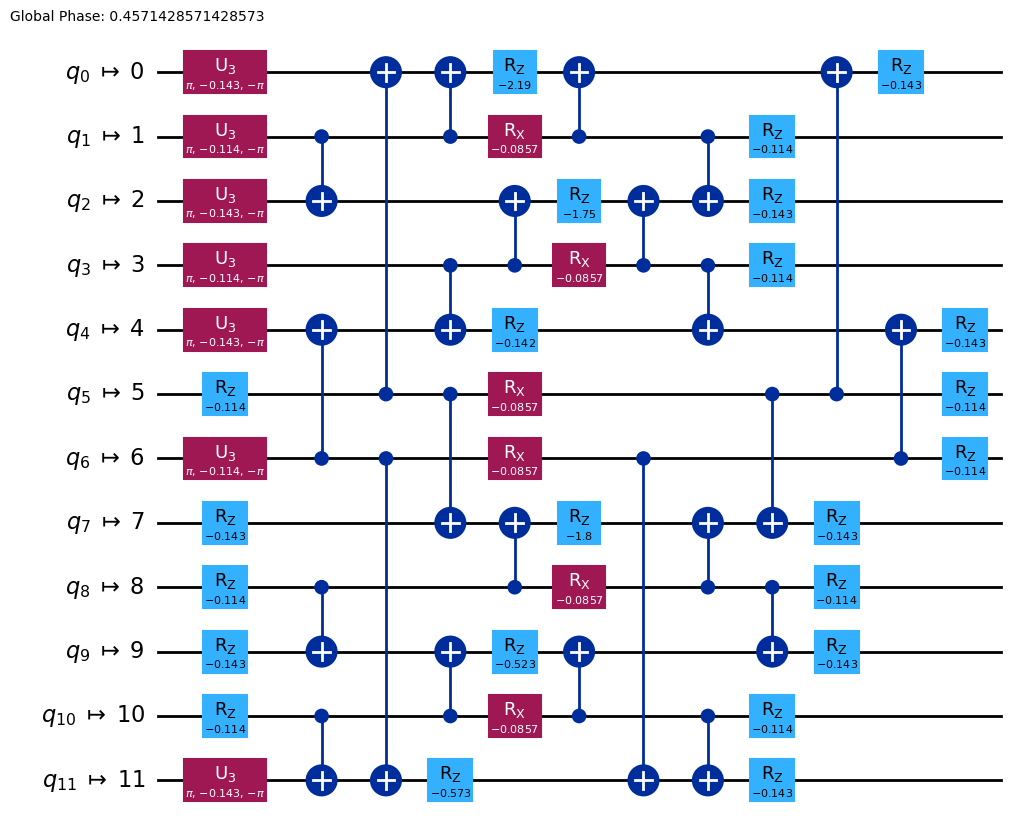

In [8]:
from qiskit_aer import AerSimulator

sampler_options = {"default_shots": 50000}

simulator_options = {
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": 512,
    "matrix_product_state_truncation_threshold": 1e-12
}

# fake_backend = AerSimulator(**simulator_options, target=backend.target)
fake_backend = AerSimulator(**simulator_options)

from z2hex.circs import erradj_string_quench_simulation_circuits_eplg, odr_compuncomp_circuits_eplg
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, steps, fake_backend, optimization_level, eplg_absolute, g, first_layout_qubit, x_basis, False, max_layers)
        physical_circuits = erradj_string_quench_simulation_circuits_eplg(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "eplg": eplg_absolute} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (lattice, J, h, lamb, final_time, steps, fake_backend, eplg_absolute, g, string_arr, first_layout_qubit, x_basis, False, max_layers)
            this_odr_circuits.append(odr_compuncomp_circuits_eplg(*odr_func_args))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

circuits[0][0][1].draw(output="mpl", idle_wires=False)

In [10]:
from utils.postselection import simulate_postselected_operators
from z2hex.plotting import local_observable_plot, local_obs_anim
from itertools import product

sampler_options = sampler_options = {
    "default_shots": 50000,
}

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

observables = simulate_postselected_operators(fake_backend, sampler_options, circuits[0][0], postselection_operators_funcs[0], observable_generating_funcs[0])
local_obs_anim((1 - observables)/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, filepath=f"z2hex_string_quench_simulation_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4")

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e